# 01 — EDA, preprocesamiento y feature engineering

El análisis se limita a los grupos `10 a 14 años` y `15 a 19 años`, utilizados como aproximación estadística de sexto grado a bachillerato.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.proyecto_ml import (
    COLUMNAS_CONTEO, cargar_tabla_original, filtrar_nivel_distrito,
    filtrar_sexto_bachillerato, localizar_raiz, preparar_dataset_analitico,
)

RAIZ = localizar_raiz()
RAW = RAIZ / "data" / "raw"
PROCESSED = RAIZ / "data" / "processed"
FIGURES = RAIZ / "outputs" / "figures"
TABLES = RAIZ / "outputs" / "tables"
for carpeta in [PROCESSED, FIGURES, TABLES]: carpeta.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

df = preparar_dataset_analitico(
    filtrar_sexto_bachillerato(
        filtrar_nivel_distrito(cargar_tabla_original(RAW / "TAB_EDU_1.xlsx"))
    )
)
print("Dataset analítico delimitado:", df.shape)
df.head()

Dataset analítico delimitado: (522, 22)


,departamento,municipio,distrito,grupo_etario,ha_asistido_hombres,ha_asistido_mujeres,ha_asistido_total,nunca_asistio_hombres,nunca_asistio_mujeres,nunca_asistio_total,no_sabe_hombres,no_sabe_mujeres,no_sabe_total,poblacion_total,edad_min,edad_max,edad_media,nivel_educativo_aproximado,es_bachillerato_aproximado,codigo_departamento,grupo_geografico,tasa_nunca_asistio
0,01 - Ahuachapán,01- Ahuachapán Centro,01 - Ahuachapán,10 a 14 años,184,195,379,43,29,72,2,0,2,453,10,14,12.0,Sexto a noveno grado (aprox.),0,01,01 - Ahuachapán | 01- Ahuachapán Centro | 01 -...,0.158940
1,01 - Ahuachapán,01- Ahuachapán Centro,01 - Ahuachapán,15 a 19 años,1445,1566,3011,59,39,98,2,4,6,3115,15,19,17.0,Bachillerato (aprox.),1,01,01 - Ahuachapán | 01- Ahuachapán Centro | 01 -...,0.031461
2,01 - Ahuachapán,01- Ahuachapán Centro,02 - Apaneca,10 a 14 años,11,15,26,2,0,2,1,0,1,29,10,14,12.0,Sexto a noveno grado (aprox.),0,01,01 - Ahuachapán | 01- Ahuachapán Centro | 02 -...,0.068966
3,01 - Ahuachapán,01- Ahuachapán Centro,02 - Apaneca,15 a 19 años,118,116,234,3,3,6,3,0,3,243,15,19,17.0,Bachillerato (aprox.),1,01,01 - Ahuachapán | 01- Ahuachapán Centro | 02 -...,0.024691
4,01 - Ahuachapán,01- Ahuachapán Centro,04 - Concepción de Ataco,10 a 14 años,14,22,36,10,3,13,0,0,0,49,10,14,12.0,Sexto a noveno grado (aprox.),0,01,01 - Ahuachapán | 01- Ahuachapán Centro | 04 -...,0.265306


## 1. Calidad, nulos y duplicados

In [2]:
resumen_calidad = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje_nulos": (df.isna().mean() * 100).round(2),
    "unicos": df.nunique(dropna=True),
}).sort_values("porcentaje_nulos", ascending=False)
print("Duplicados exactos:", int(df.duplicated().sum()))
resumen_calidad.head(25)

Duplicados exactos: 0


,nulos,porcentaje_nulos,unicos
departamento,0,0.0,14
municipio,0,0.0,44
distrito,0,0.0,262
grupo_etario,0,0.0,2
ha_asistido_hombres,0,0.0,237
ha_asistido_mujeres,0,0.0,232
ha_asistido_total,0,0.0,306
nunca_asistio_hombres,0,0.0,48
nunca_asistio_mujeres,0,0.0,36
nunca_asistio_total,0,0.0,65


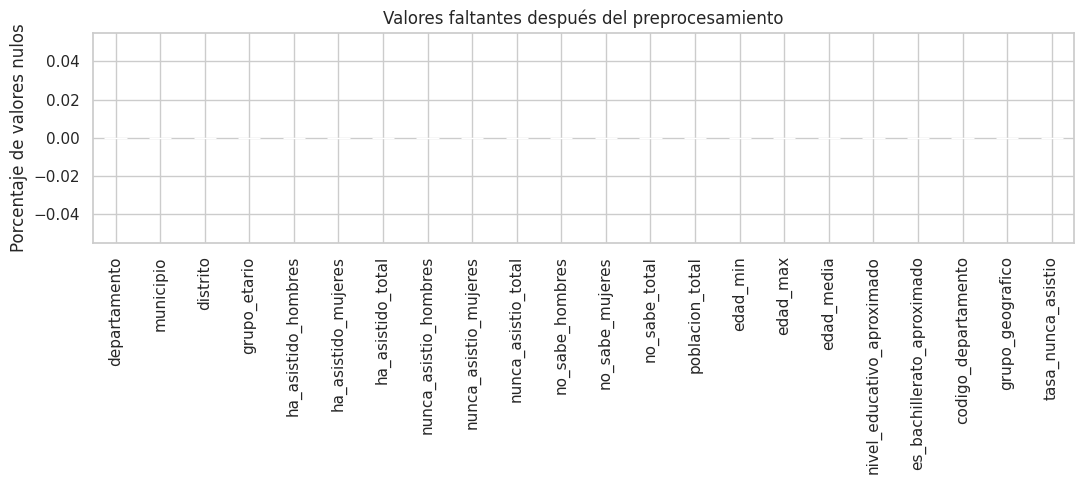

In [3]:
plt.figure(figsize=(11, 5))
(df.isna().mean().mul(100).sort_values(ascending=False)).plot(kind="bar")
plt.ylabel("Porcentaje de valores nulos")
plt.title("Valores faltantes después del preprocesamiento")
plt.tight_layout()
plt.savefig(FIGURES / "01_valores_faltantes.png", dpi=160)
plt.show()

Los conteos quedan completos después de interpretar los blancos censales como cero. No se eliminan observaciones del alcance por valores faltantes.

## 2. Estadísticas descriptivas

In [4]:
columnas_resumen = ["poblacion_total", "ha_asistido_total", "nunca_asistio_total", "no_sabe_total", "tasa_nunca_asistio"]
estadisticas = df[columnas_resumen].describe().T
estadisticas.to_csv(TABLES / "estadisticas_descriptivas_alcance.csv", encoding="utf-8-sig")
estadisticas

,count,mean,std,min,25%,50%,75%,max
poblacion_total,522.0,305.459770,533.760101,1.0,44.000000,115.000000,338.75000,4933.0
ha_asistido_total,522.0,289.490421,514.785497,0.0,38.250000,106.000000,325.25000,4774.0
nunca_asistio_total,522.0,13.352490,17.376001,0.0,3.000000,7.500000,15.00000,127.0
no_sabe_total,522.0,2.616858,7.621488,0.0,0.000000,1.000000,3.00000,140.0
tasa_nunca_asistio,522.0,0.079210,0.083620,0.0,0.024831,0.045261,0.11924,1.0


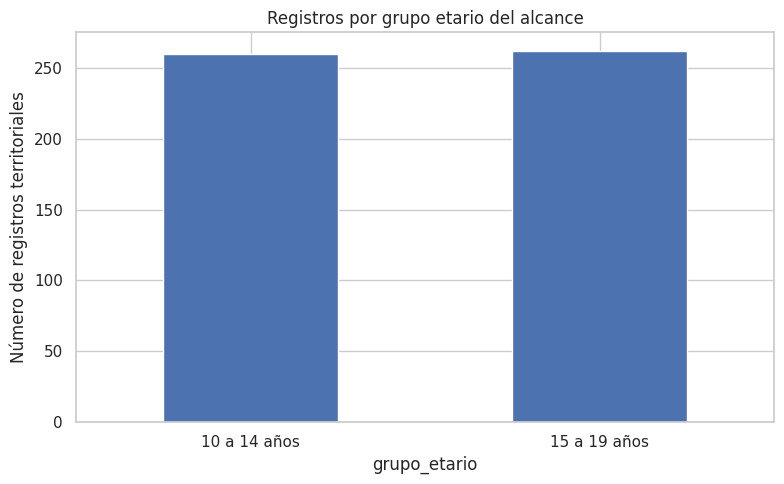

In [5]:
conteo_grupo = df["grupo_etario"].value_counts().sort_index()
plt.figure(figsize=(8, 5))
conteo_grupo.plot(kind="bar")
plt.ylabel("Número de registros territoriales")
plt.title("Registros por grupo etario del alcance")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES / "02_registros_por_grupo_etario.png", dpi=160)
plt.show()

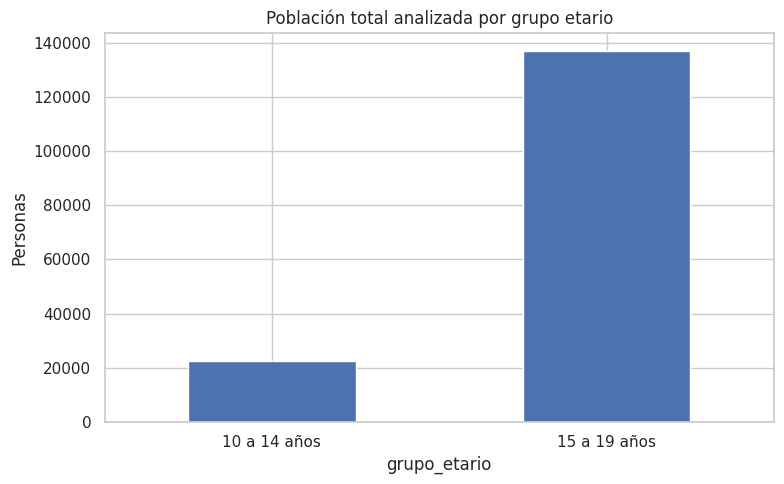

grupo_etario
10 a 14 años     22614
15 a 19 años    136836
Name: poblacion_total, dtype: int64

In [6]:
poblacion_grupo = df.groupby("grupo_etario", observed=True)["poblacion_total"].sum().sort_index()
plt.figure(figsize=(8, 5))
poblacion_grupo.plot(kind="bar")
plt.ylabel("Personas")
plt.title("Población total analizada por grupo etario")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES / "03_poblacion_por_grupo_etario.png", dpi=160)
plt.show()
poblacion_grupo

## 3. Distribución de la tasa de nunca asistencia

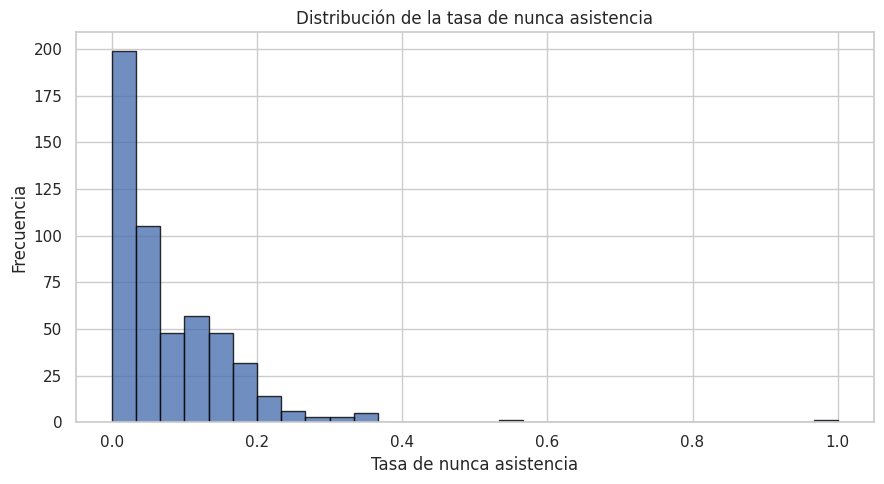

In [7]:
plt.figure(figsize=(9, 5))
plt.hist(df["tasa_nunca_asistio"], bins=30, edgecolor="black", alpha=0.8)
plt.xlabel("Tasa de nunca asistencia")
plt.ylabel("Frecuencia")
plt.title("Distribución de la tasa de nunca asistencia")
plt.tight_layout()
plt.savefig(FIGURES / "04_distribucion_tasa_nunca_asistio.png", dpi=160)
plt.show()

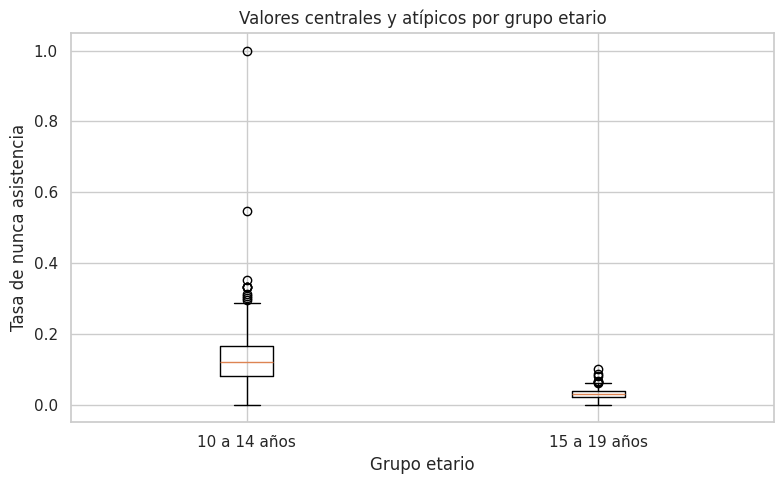

In [8]:
grupos_box = [
    df.loc[df["grupo_etario"].eq(grupo), "tasa_nunca_asistio"].values
    for grupo in sorted(df["grupo_etario"].unique())
]
plt.figure(figsize=(8, 5))
plt.boxplot(grupos_box, tick_labels=sorted(df["grupo_etario"].unique()))
plt.xlabel("Grupo etario")
plt.ylabel("Tasa de nunca asistencia")
plt.title("Valores centrales y atípicos por grupo etario")
plt.tight_layout()
plt.savefig(FIGURES / "05_boxplot_tasa_grupo.png", dpi=160)
plt.show()

In [9]:
q1 = df["tasa_nunca_asistio"].quantile(0.25)
q3 = df["tasa_nunca_asistio"].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
resumen_iqr = pd.DataFrame({
    "Q1": [q1], "Q3": [q3], "IQR": [iqr], "limite_superior": [limite_superior],
    "registros_atipicos_superiores": [(df["tasa_nunca_asistio"] > limite_superior).sum()],
})
resumen_iqr.to_csv(TABLES / "analisis_iqr_tasa.csv", index=False, encoding="utf-8-sig")
resumen_iqr

,Q1,Q3,IQR,limite_superior,registros_atipicos_superiores
0,0.024831,0.11924,0.094409,0.260854,14


## 4. Comparaciones territoriales y etarias

Las tasas agregadas se calculan usando la suma de personas que nunca asistieron dividida entre la suma de población, evitando promediar porcentajes con poblaciones muy distintas.

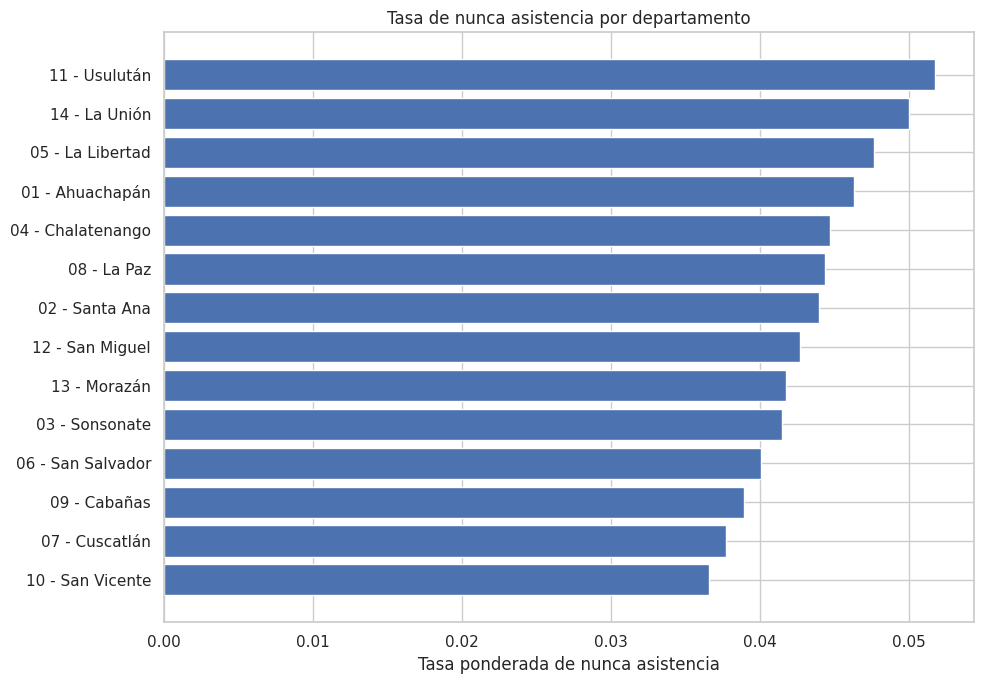

In [10]:
dep = df.groupby("departamento", as_index=False).agg(
    nunca_asistio_total=("nunca_asistio_total", "sum"),
    poblacion_total=("poblacion_total", "sum"),
)
dep["tasa_ponderada"] = dep["nunca_asistio_total"] / dep["poblacion_total"]
dep = dep.sort_values("tasa_ponderada", ascending=True)
plt.figure(figsize=(10, 7))
plt.barh(dep["departamento"], dep["tasa_ponderada"])
plt.xlabel("Tasa ponderada de nunca asistencia")
plt.title("Tasa de nunca asistencia por departamento")
plt.tight_layout()
plt.savefig(FIGURES / "06_tasa_por_departamento.png", dpi=160)
plt.show()

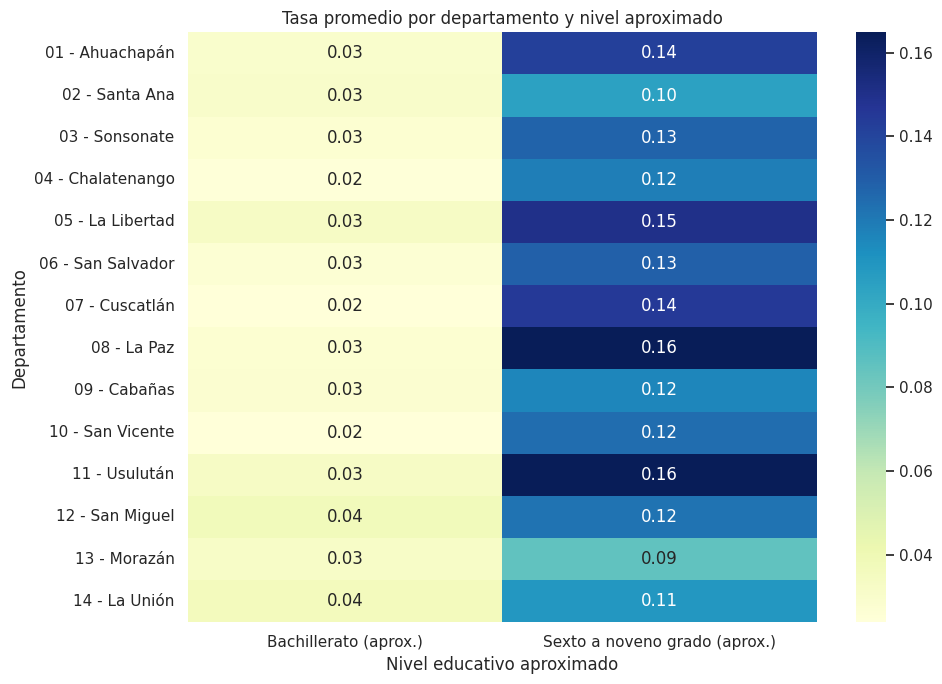

In [11]:
tabla_heat = df.pivot_table(
    index="departamento", columns="nivel_educativo_aproximado",
    values="tasa_nunca_asistio", aggfunc="mean"
)
plt.figure(figsize=(10, 7))
sns.heatmap(tabla_heat, annot=True, fmt=".2f", cmap="YlGnBu")
plt.xlabel("Nivel educativo aproximado")
plt.ylabel("Departamento")
plt.title("Tasa promedio por departamento y nivel aproximado")
plt.tight_layout()
plt.savefig(FIGURES / "07_heatmap_departamento_nivel.png", dpi=160)
plt.show()

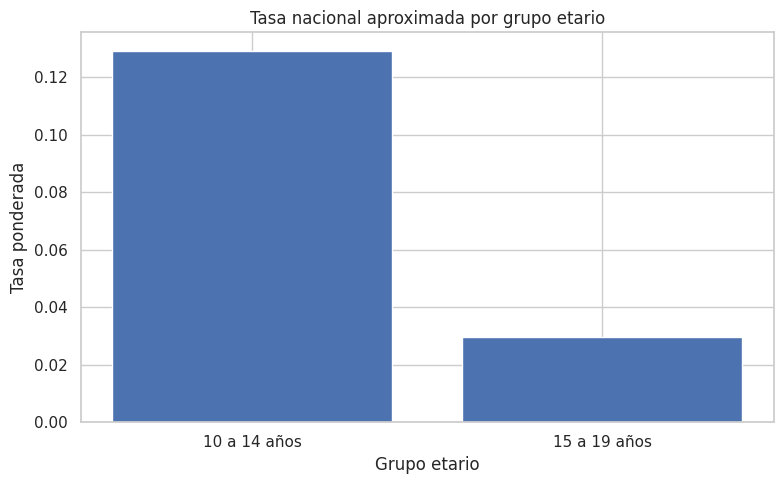

,grupo_etario,nunca_asistio_total,poblacion_total,tasa_ponderada
0,10 a 14 años,2919,22614,0.129079
1,15 a 19 años,4051,136836,0.029605


In [12]:
grupo = df.groupby("grupo_etario", as_index=False).agg(
    nunca_asistio_total=("nunca_asistio_total", "sum"),
    poblacion_total=("poblacion_total", "sum"),
)
grupo["tasa_ponderada"] = grupo["nunca_asistio_total"] / grupo["poblacion_total"]
plt.figure(figsize=(8, 5))
plt.bar(grupo["grupo_etario"], grupo["tasa_ponderada"])
plt.xlabel("Grupo etario")
plt.ylabel("Tasa ponderada")
plt.title("Tasa nacional aproximada por grupo etario")
plt.tight_layout()
plt.savefig(FIGURES / "08_tasa_ponderada_grupo.png", dpi=160)
plt.show()
grupo

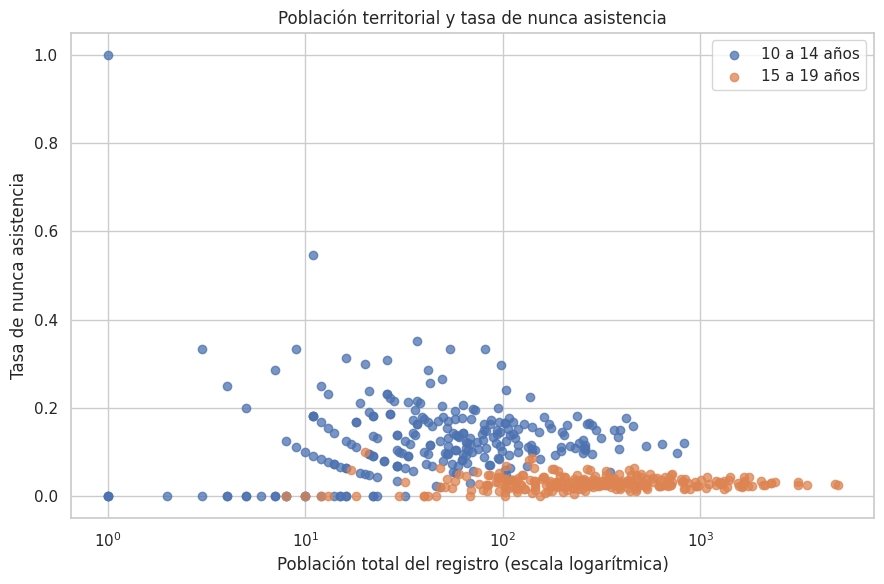

In [13]:
plt.figure(figsize=(9, 6))
for nombre, sub in df.groupby("grupo_etario"):
    plt.scatter(sub["poblacion_total"], sub["tasa_nunca_asistio"], alpha=0.75, label=nombre)
plt.xscale("log")
plt.xlabel("Población total del registro (escala logarítmica)")
plt.ylabel("Tasa de nunca asistencia")
plt.title("Población territorial y tasa de nunca asistencia")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES / "09_scatter_poblacion_tasa.png", dpi=160)
plt.show()

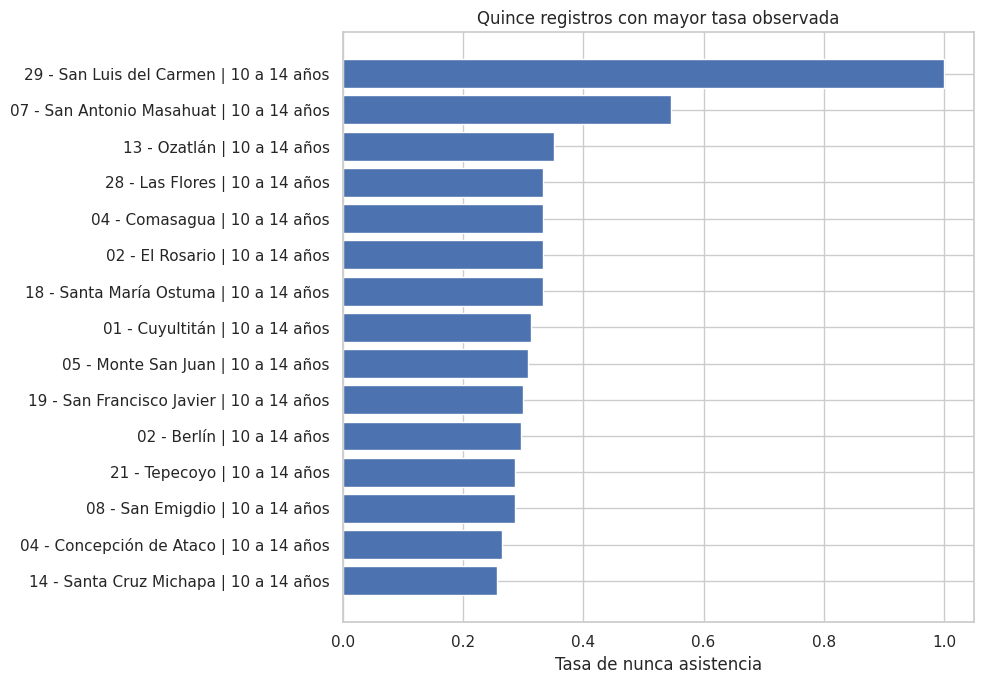

In [14]:
top = df.nlargest(15, "tasa_nunca_asistio").copy()
top["etiqueta"] = top["distrito"] + " | " + top["grupo_etario"]
plt.figure(figsize=(10, 7))
plt.barh(top["etiqueta"][::-1], top["tasa_nunca_asistio"][::-1])
plt.xlabel("Tasa de nunca asistencia")
plt.title("Quince registros con mayor tasa observada")
plt.tight_layout()
plt.savefig(FIGURES / "10_top_registros_tasa.png", dpi=160)
plt.show()

## 5. Correlaciones y feature engineering

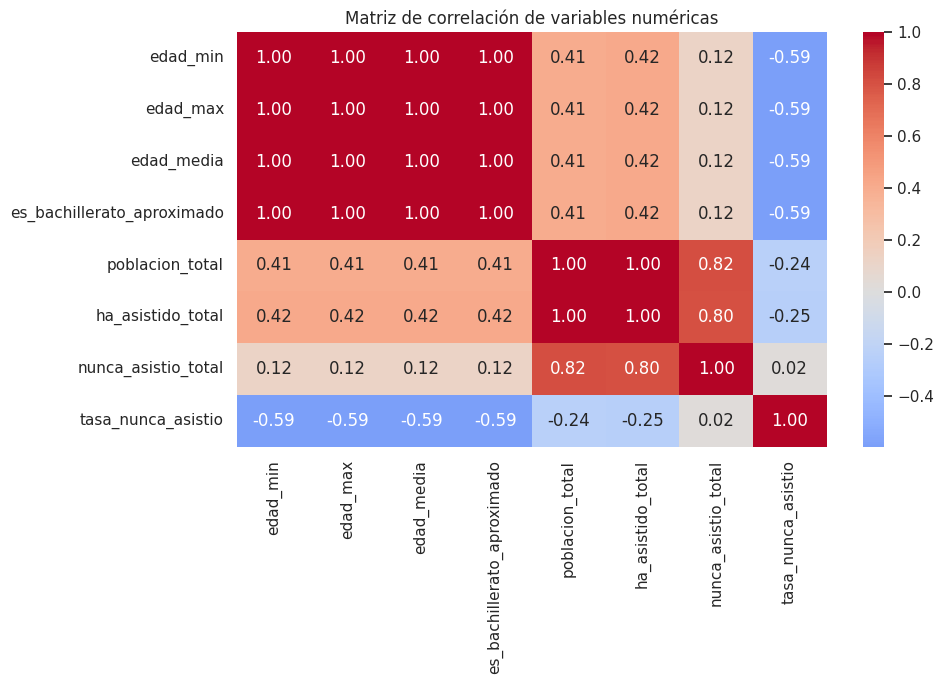

In [15]:
corr_cols = ["edad_min", "edad_max", "edad_media", "es_bachillerato_aproximado", "poblacion_total", "ha_asistido_total", "nunca_asistio_total", "tasa_nunca_asistio"]
plt.figure(figsize=(10, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.savefig(FIGURES / "11_matriz_correlacion.png", dpi=160)
plt.show()

In [16]:
diccionario_features = pd.DataFrame([
    ["edad_min", "Edad mínima del grupo quinquenal", "Numérica"],
    ["edad_max", "Edad máxima del grupo quinquenal", "Numérica"],
    ["edad_media", "Punto medio del grupo quinquenal", "Numérica"],
    ["nivel_educativo_aproximado", "Proxy de sexto–noveno o bachillerato", "Categórica"],
    ["es_bachillerato_aproximado", "1 para 15–19; 0 para 10–14", "Binaria"],
    ["codigo_departamento", "Código extraído del nombre del departamento", "Categórica"],
    ["grupo_geografico", "Clave territorio departamento–municipio–distrito", "Categórica/grupo"],
    ["tasa_nunca_asistio", "Nunca asistió total / población total", "Numérica/objetivo base"],
], columns=["feature", "descripcion", "tipo"])
diccionario_features.to_csv(TABLES / "diccionario_features_creadas.csv", index=False, encoding="utf-8-sig")
diccionario_features

,feature,descripcion,tipo
0,edad_min,Edad mínima del grupo quinquenal,Numérica
1,edad_max,Edad máxima del grupo quinquenal,Numérica
2,edad_media,Punto medio del grupo quinquenal,Numérica
3,nivel_educativo_aproximado,Proxy de sexto–noveno o bachillerato,Categórica
4,es_bachillerato_aproximado,1 para 15–19; 0 para 10–14,Binaria
5,codigo_departamento,Código extraído del nombre del departamento,Categórica
6,grupo_geografico,Clave territorio departamento–municipio–distrito,Categórica/grupo
7,tasa_nunca_asistio,Nunca asistió total / población total,Numérica/objetivo base


In [17]:
ruta_salida = PROCESSED / "dataset_analitico_6to_bachillerato.csv"
df.to_csv(ruta_salida, index=False, encoding="utf-8-sig")
print("Archivo guardado:", ruta_salida)
print("Dimensiones finales:", df.shape)
print("Nulos finales:", int(df.isna().sum().sum()))

Archivo guardado: /mnt/data/ML_No_Asistencia_6to_Bachillerato_SV/data/processed/dataset_analitico_6to_bachillerato.csv
Dimensiones finales: (522, 22)
Nulos finales: 0


## Conclusión del EDA

El alcance queda reducido a dos grupos etarios y conserva cobertura nacional a nivel de distrito. La tasa presenta asimetría y valores atípicos, por lo que las métricas de clasificación deben interpretarse junto con F1, recall, ROC-AUC y balanced accuracy, no únicamente accuracy.